# Modern Data Analysis — Task 4
## Seaborn: Statistical Visualization and Analysis of the Tips Dataset

**Student:** Odumosu Oluwasomidotun Adebowale  
**Course:** Modern Data Analysis  
**Assignment:** Task 4 — Introduction to Seaborn

### Aim
This notebook follows the supplied lecture's Seaborn introduction, runs the original `relplot` example, and extends it with descriptive statistics, tip-percentage calculations, additional visualizations, and correlation analysis.

### Questions explored
1. How are the restaurant bill and tip related?
2. How do tip percentages vary by day and meal time?
3. What can descriptive statistics and correlations tell us about the numeric variables?

> **Data note:** The `tips` dataset is Seaborn's example dataset. It contains sample restaurant bills and tips; it should not be treated as a representative study of every restaurant or customer.


## 1. Environment and required libraries

This notebook is designed for **Google Colab**. Run the cells from top to bottom. The libraries below support data handling, statistical graphics, and numerical calculations.


### Validation note

The analysis cells and plots were executed successfully against the standard 244-row Seaborn `tips` dataset. The validation runtime had no internet access, so the run used the identical canonical dataset bundled with Plotly; the submitted loading cell below retains the assignment's original `sns.load_dataset("tips")` method. In Google Colab, that original method requires an internet connection. All analysis code cells completed without execution errors.

In [1]:
# Install the core packages if they are not already available.
%pip -q install seaborn pandas matplotlib numpy


In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Consistent, presentation-friendly styling
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "font.size": 10,
})

print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("Libraries imported successfully.")


pandas: 2.2.3
seaborn: 0.13.2
Libraries imported successfully.


## 2. Load the dataset

The lecture uses `sns.load_dataset("tips")`. We retain that approach so the notebook follows the supplied teaching material. This cell also checks that the dataset was loaded and displays a few rows.


In [3]:
tips = sns.load_dataset("tips")

if tips.empty:
    raise ValueError("The tips dataset loaded, but it contains no rows.")

print(f"Dataset shape: {tips.shape[0]} rows × {tips.shape[1]} columns")
display(tips.head())


Dataset shape: 244 rows × 7 columns


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 3. Understand the data

Before plotting, inspect the column names, data types, missing values, and duplicate rows. These checks help us understand the data and avoid making calculations without checking the input. A duplicate-row count is reported for review; identical records should not be removed automatically because they may represent separate real transactions.


In [4]:
print("Column names:")
print(tips.columns.tolist())

print("\nData types and non-null counts:")
tips.info()

print("\nMissing values by column:")
display(tips.isna().sum().rename("missing_values").to_frame())

print(f"\nDuplicate rows: {tips.duplicated().sum()}")

print("\nCategorical values:")
for column in ["sex", "smoker", "day", "time"]:
    if column in tips.columns:
        print(f"{column}: {tips[column].dropna().unique().tolist()}")


Column names:
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Missing values by column:


,missing_values
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0



Duplicate rows: 1

Categorical values:
sex: ['Female', 'Male']
smoker: ['No', 'Yes']
day: ['Sun', 'Sat', 'Thur', 'Fri']
time: ['Dinner', 'Lunch']


## 4. The original Seaborn `relplot` example

This is the example shown in the supplied lecture. It maps the bill to the x-axis and the tip to the y-axis, creates separate panels for lunch and dinner, uses color and marker style for smoking status, and uses point size for party size.

**How to read it**
- `data=tips`: use the tips DataFrame.
- `x="total_bill"` and `y="tip"`: compare bill amounts with tip amounts.
- `col="time"`: create a separate panel for each meal time.
- `hue="smoker"`: distinguish smoking-status categories by color.
- `style="smoker"`: distinguish them by marker shape.
- `size="size"`: map party size to marker size.


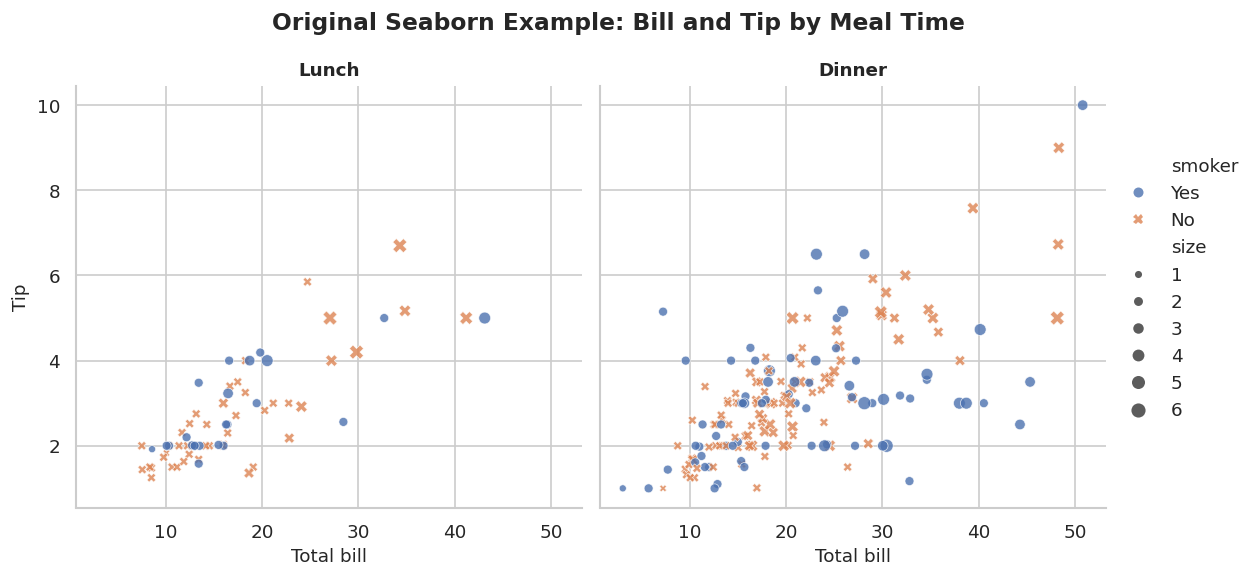

In [5]:
# Original example from the lecture
g = sns.relplot(
    data=tips,
    x="total_bill",
    y="tip",
    col="time",
    hue="smoker",
    style="smoker",
    size="size",
    height=4.5,
    aspect=1.05,
    alpha=0.8,
)
g.set_axis_labels("Total bill", "Tip")
g.set_titles("{col_name}")
g.figure.suptitle("Original Seaborn Example: Bill and Tip by Meal Time", y=1.06, fontsize=14, fontweight="bold")
plt.show()


## 5. Descriptive statistics

Descriptive statistics summarize the numeric variables. The mean is the arithmetic average, the median is the middle observation, and the standard deviation describes how spread out the values are around their mean. The quartiles show the 25th, 50th, and 75th percentiles.


In [6]:
numeric_columns = ["total_bill", "tip", "size"]
descriptive_stats = tips[numeric_columns].describe().T
descriptive_stats["median"] = tips[numeric_columns].median()
descriptive_stats = descriptive_stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]
].round(3)

display(descriptive_stats)


,count,mean,median,std,min,25%,50%,75%,max
total_bill,244.0,19.786,17.795,8.902,3.07,13.348,17.795,24.127,50.81
tip,244.0,2.998,2.900,1.384,1.00,2.000,2.900,3.562,10.00
size,244.0,2.570,2.000,0.951,1.00,2.000,2.000,3.000,6.00


## 6. Calculate tip percentage

Tip percentage is calculated for each bill as:

\[
\text{Tip percentage} = \frac{\text{Tip}}{\text{Total bill}} \times 100
\]

The calculation uses each row's own bill amount. We first check for zero or missing bill values so that the division is valid.


In [7]:
# Check the denominator before calculating a percentage.
zero_bill_count = int((tips["total_bill"] == 0).sum())
missing_bill_count = int(tips["total_bill"].isna().sum())

print(f"Rows with a zero total bill: {zero_bill_count}")
print(f"Rows with a missing total bill: {missing_bill_count}")

# A zero bill cannot be used as a denominator, so it is treated as missing for this calculation.
tips["tip_pct"] = (
    tips["tip"].div(tips["total_bill"].where(tips["total_bill"].ne(0))) * 100
)

print("\nTip percentage summary (%):")
display(tips["tip_pct"].describe().round(2).to_frame("tip_pct"))

print("\nExample calculations:")
display(tips[["total_bill", "tip", "tip_pct", "day", "time"]].head(10).round(2))


Rows with a zero total bill: 0
Rows with a missing total bill: 0

Tip percentage summary (%):


,tip_pct
count,244.00
mean,16.08
std,6.11
min,3.56
25%,12.91
50%,15.48
75%,19.15
max,71.03



Example calculations:


,total_bill,tip,tip_pct,day,time
0,16.99,1.01,5.94,Sun,Dinner
1,10.34,1.66,16.05,Sun,Dinner
2,21.01,3.50,16.66,Sun,Dinner
3,23.68,3.31,13.98,Sun,Dinner
4,24.59,3.61,14.68,Sun,Dinner
5,25.29,4.71,18.62,Sun,Dinner
6,8.77,2.00,22.81,Sun,Dinner
7,26.88,3.12,11.61,Sun,Dinner
8,15.04,1.96,13.03,Sun,Dinner
9,14.78,3.23,21.85,Sun,Dinner


## 7. Visualisation 1 — Distribution of restaurant bills

A histogram shows how often bill amounts fall into different ranges. The KDE curve is a smoothed estimate of the distribution. This helps us see whether most bills are small, moderate, or large and whether the distribution has a long tail.


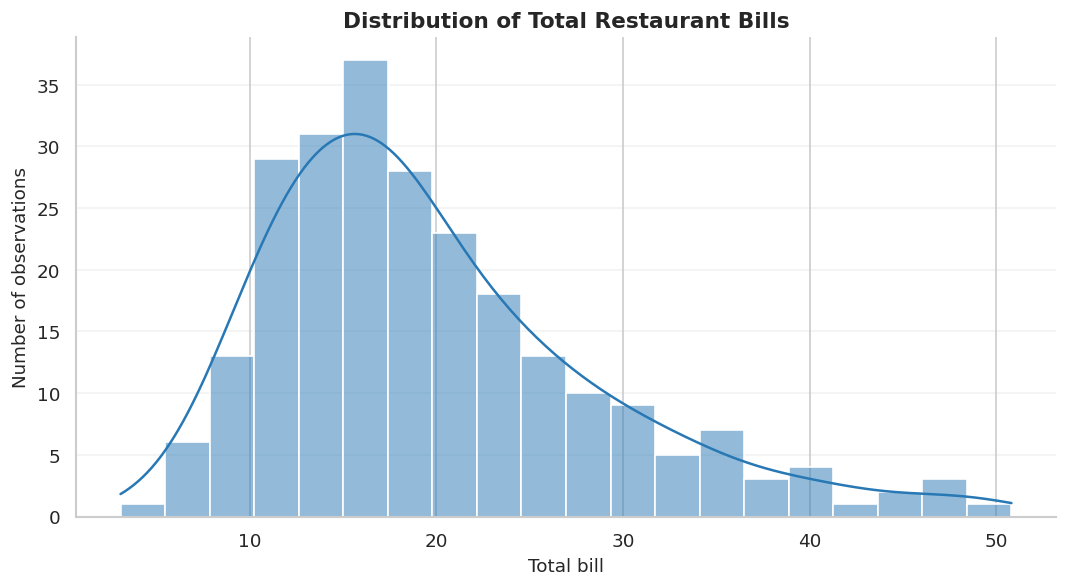

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=tips, x="total_bill", bins=20, kde=True, color="#2878B5", ax=ax)
ax.set_title("Distribution of Total Restaurant Bills")
ax.set_xlabel("Total bill")
ax.set_ylabel("Number of observations")
ax.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()


## 8. Visualisation 2 — Bill amount versus tip, with a trend line

The scatter plot displays individual bills and tips. The fitted regression line summarizes the overall linear trend. A positive slope would indicate that larger bills tend to be associated with larger tip amounts; it does not prove that one variable causes the other.


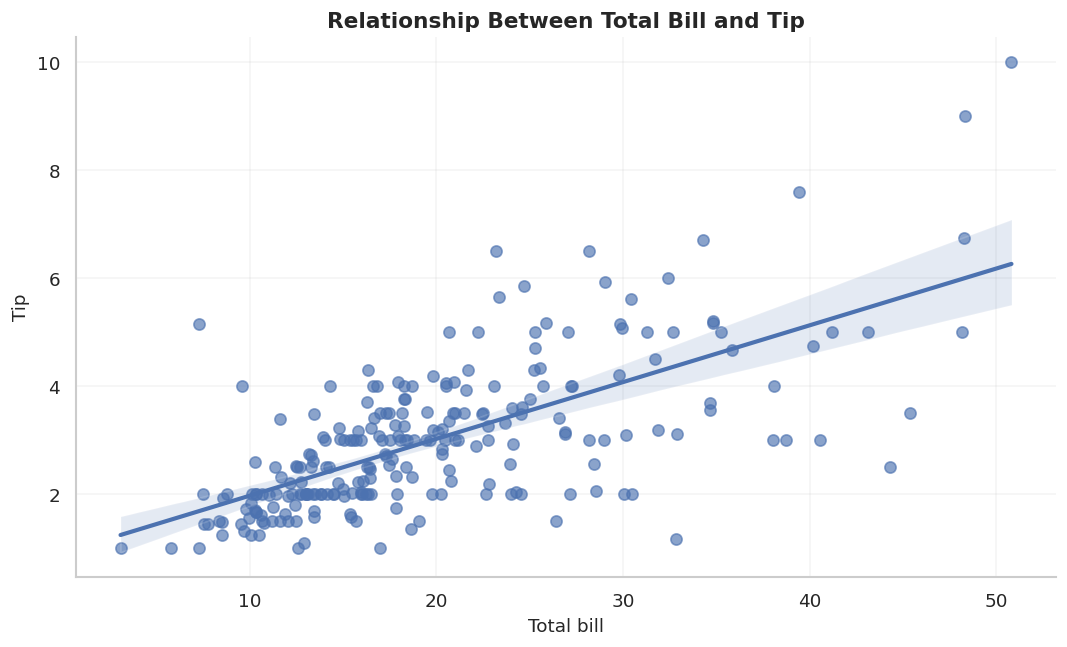

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(
    data=tips,
    x="total_bill",
    y="tip",
    scatter_kws={"alpha": 0.65, "s": 45},
    line_kws={"linewidth": 2.5},
    ax=ax,
)
ax.set_title("Relationship Between Total Bill and Tip")
ax.set_xlabel("Total bill")
ax.set_ylabel("Tip")
ax.grid(alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()


## 9. Visualisation 3 — Tip percentage by day

A box plot compares the distribution of tip percentages across days. The line inside each box is the median; the box covers the interquartile range. Points beyond the whiskers may be potential outliers, not necessarily errors.


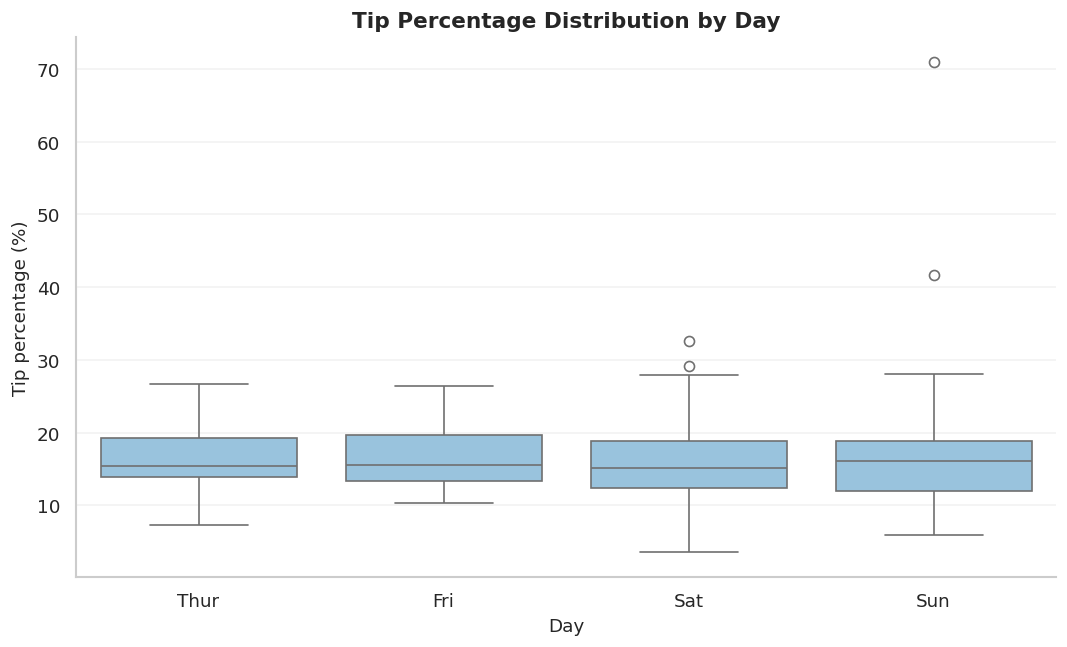

In [10]:
day_order = ["Thur", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(
    data=tips,
    x="day",
    y="tip_pct",
    order=[d for d in day_order if d in tips["day"].astype(str).unique()],
    color="#8EC5E8",
    showfliers=True,
    ax=ax,
)
ax.set_title("Tip Percentage Distribution by Day")
ax.set_xlabel("Day")
ax.set_ylabel("Tip percentage (%)")
ax.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()


## 10. Visualisation 4 — Average tip percentage by meal time

This bar chart compares the mean tip percentage for lunch and dinner. A mean can be influenced by unusually high or low observations, so it should be read alongside the distribution plots and group summary table.


,observations,mean_tip_pct,median_tip_pct
time,,,
Lunch,68,16.41,15.41
Dinner,176,15.95,15.54


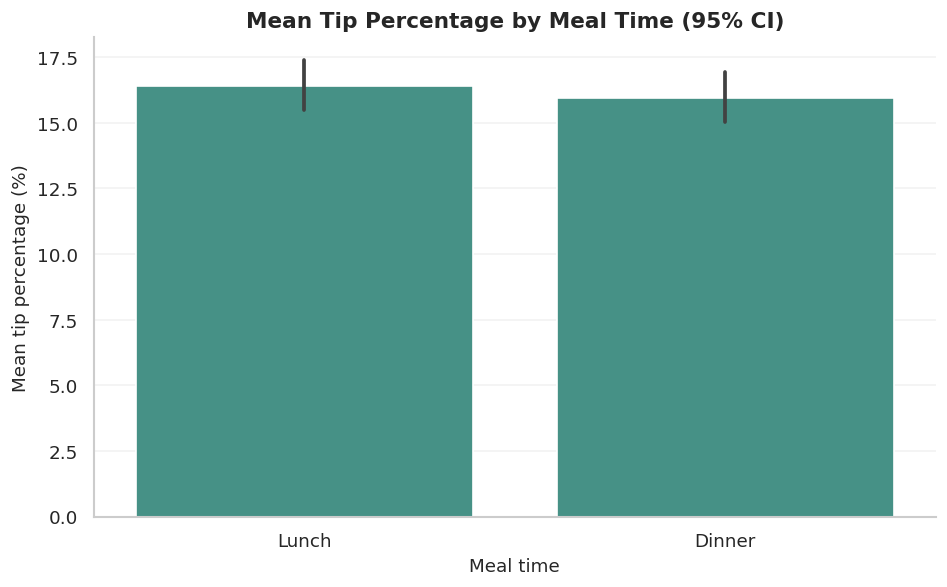

In [11]:
meal_summary = (
    tips.groupby("time", observed=True)
        .agg(
            observations=("tip_pct", "count"),
            mean_tip_pct=("tip_pct", "mean"),
            median_tip_pct=("tip_pct", "median"),
        )
        .sort_values("mean_tip_pct", ascending=False)
)
display(meal_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=tips,
    x="time",
    y="tip_pct",
    estimator="mean",
    errorbar=("ci", 95),
    color="#3A9D8F",
    ax=ax,
)
ax.set_title("Mean Tip Percentage by Meal Time (95% CI)")
ax.set_xlabel("Meal time")
ax.set_ylabel("Mean tip percentage (%)")
ax.grid(axis="y", alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()


## 11. Correlation analysis

Pearson correlation measures the strength and direction of a **linear association** between two numeric variables. Values range from -1 to +1: values near +1 indicate a strong positive linear association, values near -1 a strong negative association, and values near 0 little linear association.

Correlation does not establish causation. Also, the tip percentage is calculated from `tip` and `total_bill`, so correlations involving `tip_pct` should be interpreted with that mathematical relationship in mind.


,total_bill,tip,size,tip_pct
total_bill,1.000,0.676,0.598,-0.339
tip,0.676,1.000,0.489,0.342
size,0.598,0.489,1.000,-0.143
tip_pct,-0.339,0.342,-0.143,1.000


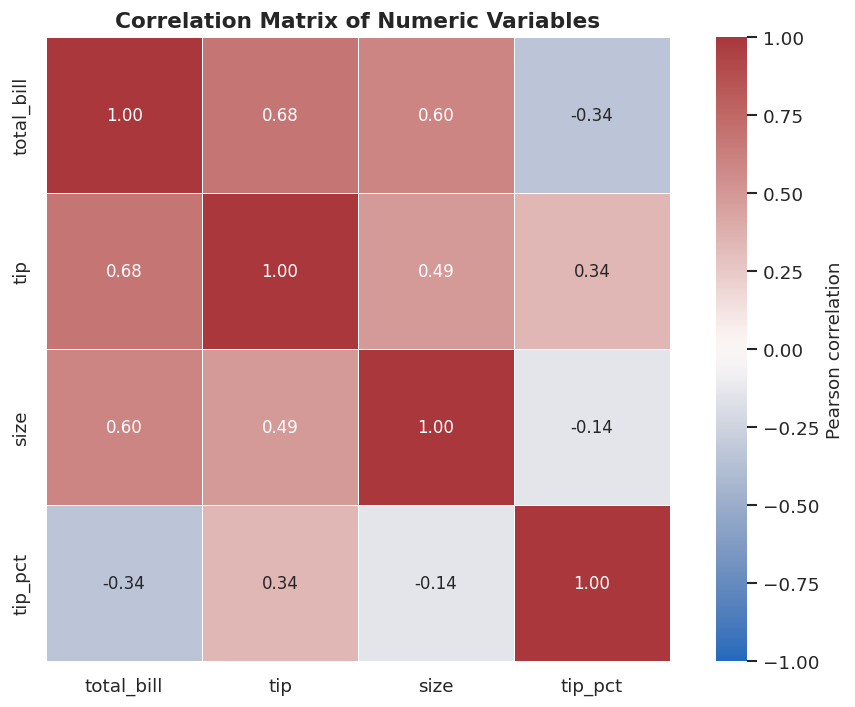

In [12]:
correlation_columns = ["total_bill", "tip", "size", "tip_pct"]
correlation_matrix = tips[correlation_columns].corr(method="pearson")
display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.6,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()


## 12. Grouped analysis — Tips by day and smoker status

This table provides context behind the visualisations by comparing sample size, average bill, average tip, and average tip percentage for each day and smoking-status group. Group sizes matter: a mean based on few observations may be less stable than one based on many.


In [13]:
group_summary = (
    tips.groupby(["day", "smoker"], observed=True)
        .agg(
            observations=("tip", "size"),
            mean_bill=("total_bill", "mean"),
            mean_tip=("tip", "mean"),
            mean_tip_pct=("tip_pct", "mean"),
            median_tip_pct=("tip_pct", "median"),
        )
        .reset_index()
        .sort_values(["day", "smoker"])
)

display(group_summary.round(2))


,day,smoker,observations,mean_bill,mean_tip,mean_tip_pct,median_tip_pct
0,Thur,Yes,17,19.19,3.03,16.39,15.38
1,Thur,No,45,17.11,2.67,16.03,15.35
2,Fri,Yes,15,16.81,2.71,17.48,17.39
3,Fri,No,4,18.42,2.81,15.17,14.92
4,Sat,Yes,42,21.28,2.88,14.79,15.36
5,Sat,No,45,19.66,3.10,15.80,15.02
6,Sun,Yes,19,24.12,3.52,18.73,13.81
7,Sun,No,57,20.51,3.17,16.01,16.17


## 13. Main findings and conclusion

The next cell produces a short conclusion from the dataset's actual computed results. This avoids writing claims before the calculations have been run.


In [14]:
# Compute findings from the data rather than assuming the outcome.
bill_tip_corr = tips[["total_bill", "tip"]].corr().iloc[0, 1]
mean_tip_pct = tips["tip_pct"].mean()
median_tip_pct = tips["tip_pct"].median()

highest_day = tips.groupby("day", observed=True)["tip_pct"].mean().idxmax()
highest_day_value = tips.groupby("day", observed=True)["tip_pct"].mean().max()

meal_means = tips.groupby("time", observed=True)["tip_pct"].mean().dropna()
if len(meal_means) >= 2:
    highest_meal = meal_means.idxmax()
    highest_meal_value = meal_means.max()
    meal_sentence = (
        f"The higher mean tip percentage by meal time is {highest_meal} "
        f"({highest_meal_value:.2f}%)."
    )
else:
    meal_sentence = "There were not enough meal-time groups to compare mean tip percentages."

print("CONCLUSION")
print("=" * 60)
print(
    f"The dataset contains {len(tips)} observations. "
    f"The mean tip percentage is {mean_tip_pct:.2f}% and the median is "
    f"{median_tip_pct:.2f}%."
)
print(
    f"The Pearson correlation between total bill and tip is {bill_tip_corr:.3f}. "
    "This describes a linear association, not a causal effect."
)
print(
    f"The day with the highest average tip percentage in this sample is "
    f"{highest_day} ({highest_day_value:.2f}%)."
)
print(meal_sentence)
print(
    "The visualisations and summaries complement one another: the plots show "
    "patterns and variation, while the tables provide numerical summaries. "
    "These results describe this sample only and should not be generalized "
    "to all restaurant customers without additional evidence."
)


CONCLUSION
The dataset contains 244 observations. The mean tip percentage is 16.08% and the median is 15.48%.
The Pearson correlation between total bill and tip is 0.676. This describes a linear association, not a causal effect.
The day with the highest average tip percentage in this sample is Fri (16.99%).
The higher mean tip percentage by meal time is Lunch (16.41%).
The visualisations and summaries complement one another: the plots show patterns and variation, while the tables provide numerical summaries. These results describe this sample only and should not be generalized to all restaurant customers without additional evidence.


## 14. Final quality checks

Run these checks before submitting. They verify the derived percentage column and confirm that the main numeric fields are present.


In [15]:
assert {"total_bill", "tip", "size", "tip_pct"}.issubset(tips.columns)
assert (tips["total_bill"].dropna() > 0).all(), "Unexpected non-positive total bill found."
valid_rows = tips["total_bill"].notna() & tips["tip"].notna() & tips["total_bill"].ne(0)
expected_pct = tips.loc[valid_rows, "tip"].div(tips.loc[valid_rows, "total_bill"]) * 100
assert np.allclose(tips.loc[valid_rows, "tip_pct"], expected_pct), "Tip percentage calculation check failed."

print("Quality checks passed.")
print(f"Rows: {len(tips)}")
print(f"Columns after analysis: {len(tips.columns)}")
print("Notebook analysis is complete.")


Quality checks passed.
Rows: 244
Columns after analysis: 8
Notebook analysis is complete.


## Validation record

- **Dataset:** 244 rows and 7 original columns; no missing values were found.
- **Derived measure:** `tip_pct = tip / total_bill × 100`; the quality-check assertion passed.
- **Key results:** mean tip percentage **16.08%**, median **15.48%**, Pearson correlation between bill and tip **0.676**.
- **Descriptive comparisons:** Friday has the highest sample mean tip percentage (**16.99%**); lunch has the higher mean by meal time (**16.41%**, versus **15.95%** for dinner).
- **Visual checks:** the original faceted `relplot`, bill histogram, bill-versus-tip regression plot, day-by-day tip-percentage box plot, meal-time bar chart, and correlation heatmap were rendered.
- **Execution status:** all analysis code cells completed without errors in the validation run.

**Interpretation caution:** Friday's mean is based on a relatively small sample, and the lunch/dinner difference is descriptive only; this notebook does not test whether that difference is statistically significant. The dataset is illustrative and should not be generalized to all restaurant customers.